In [27]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [28]:
# Use the full path to your CSV file
file_path = r"C:\Users\proba_oiuhnln\Downloads\Python assignment\WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Load dataset
df = pd.read_csv(file_path)

# Quick look at data
print(df.head())
print(df.info())


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [29]:
# Data Preprocessing

# 1. Convert TotalCharges to numeric and handle missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 2. Encode categorical variables (excluding customerID)
label_encoders = {}
for col in df.select_dtypes(include=['object']).columns:
    if col != 'customerID':
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
        label_encoders[col] = le

# 3. Separate features and target
X = df.drop(['customerID','Churn'], axis=1)
y = df['Churn']

# 4. Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Preprocessing complete ✅")
print("Feature matrix shape:", X_scaled.shape)
print("Target distribution:\n", y.value_counts())


Preprocessing complete ✅
Feature matrix shape: (7043, 19)
Target distribution:
 Churn
0    5174
1    1869
Name: count, dtype: int64


In [30]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [31]:
# Train models
log_reg = LogisticRegression(max_iter=1000)
dtree = DecisionTreeClassifier()
rf = RandomForestClassifier(n_estimators=100)

log_reg.fit(X_train, y_train)
dtree.fit(X_train, y_train)
rf.fit(X_train, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:

# Evaluate models with percentages
models = {"Logistic Regression": log_reg, "Decision Tree": dtree, "Random Forest": rf}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred) * 100  # convert to %
    
    print(f"\n{name} Results:")
    print(f"Accuracy: {acc:.2f}%")  # formatted as percentage
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    
    # Classification report with percentages
    report = classification_report(y_test, y_pred, output_dict=True)
    for label, metrics in report.items():
        if isinstance(metrics, dict):
            print(f"Class {label}: "
                  f"Precision: {metrics['precision']*100:.2f}%, "
                  f"Recall: {metrics['recall']*100:.2f}%, "
                  f"F1-Score: {metrics['f1-score']*100:.2f}%")



Logistic Regression Results:
Accuracy: 81.55%
Confusion Matrix:
 [[933 103]
 [157 216]]
Class 0: Precision: 85.60%, Recall: 90.06%, F1-Score: 87.77%
Class 1: Precision: 67.71%, Recall: 57.91%, F1-Score: 62.43%
Class macro avg: Precision: 76.65%, Recall: 73.98%, F1-Score: 75.10%
Class weighted avg: Precision: 80.86%, Recall: 81.55%, F1-Score: 81.06%

Decision Tree Results:
Accuracy: 73.10%
Confusion Matrix:
 [[841 195]
 [184 189]]
Class 0: Precision: 82.05%, Recall: 81.18%, F1-Score: 81.61%
Class 1: Precision: 49.22%, Recall: 50.67%, F1-Score: 49.93%
Class macro avg: Precision: 65.63%, Recall: 65.92%, F1-Score: 65.77%
Class weighted avg: Precision: 73.36%, Recall: 73.10%, F1-Score: 73.23%

Random Forest Results:
Accuracy: 78.92%
Confusion Matrix:
 [[937  99]
 [198 175]]
Class 0: Precision: 82.56%, Recall: 90.44%, F1-Score: 86.32%
Class 1: Precision: 63.87%, Recall: 46.92%, F1-Score: 54.10%
Class macro avg: Precision: 73.21%, Recall: 68.68%, F1-Score: 70.21%
Class weighted avg: Precisio

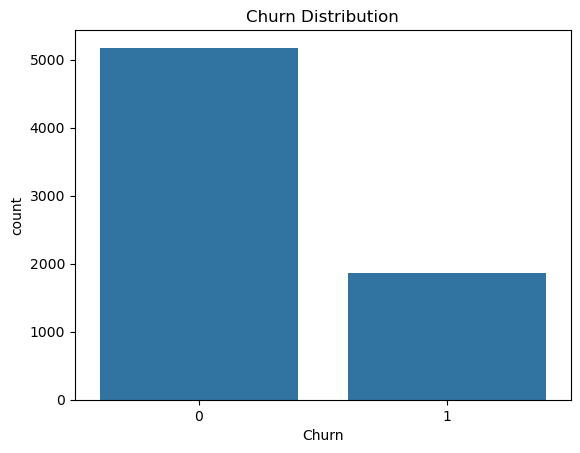

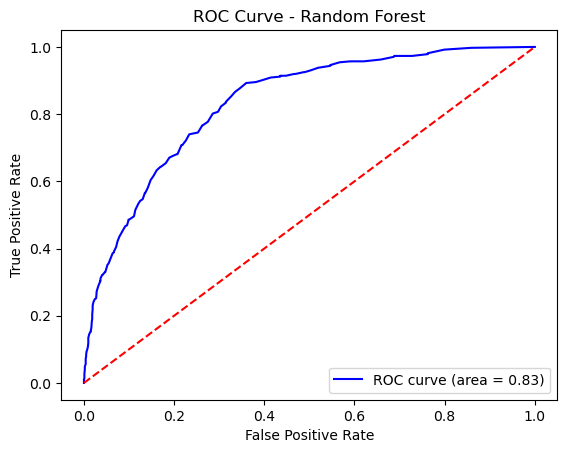

In [33]:
# Visualize churn distribution
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

# ROC Curve for Random Forest
y_pred_prob = rf.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0,1],[0,1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc="lower right")
plt.show()


In [34]:
# Test with a sample customer
sample = X_test[0].reshape(1, -1)
print("Logistic Regression Prediction:", log_reg.predict(sample))
print("Decision Tree Prediction:", dtree.predict(sample))
print("Random Forest Prediction:", rf.predict(sample))


Logistic Regression Prediction: [1]
Decision Tree Prediction: [1]
Random Forest Prediction: [1]


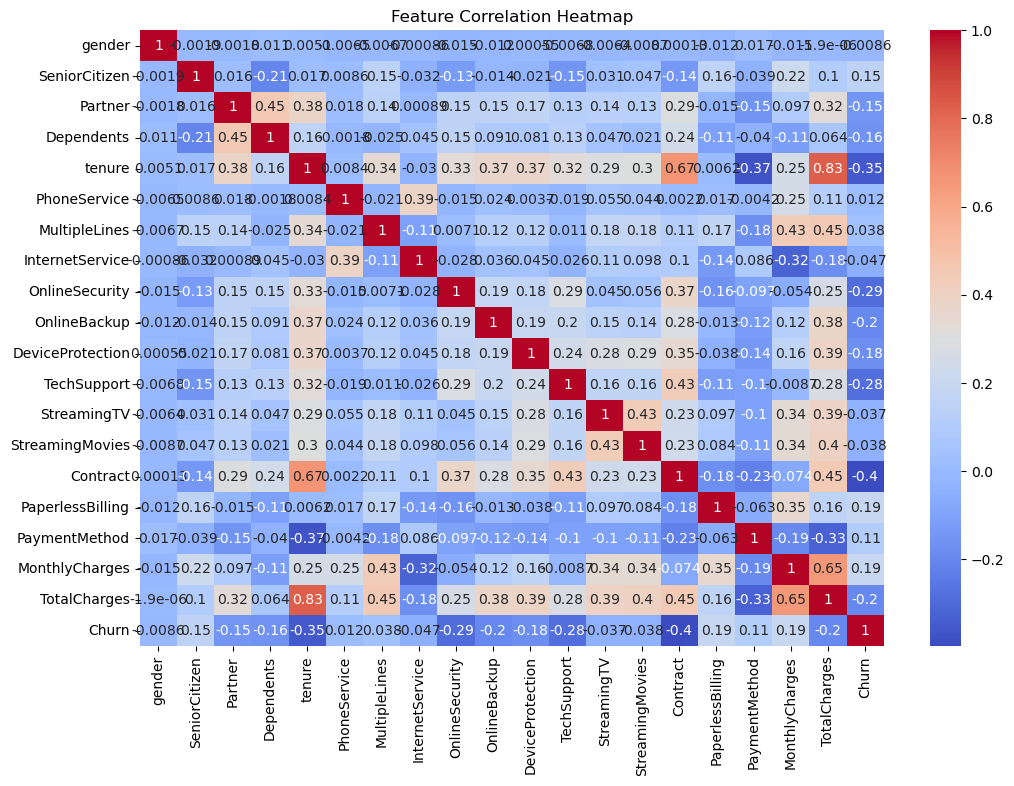

In [35]:
# Heatmap of feature correlations

# Drop non-numeric columns like customerID
numeric_df = df.drop(columns=['customerID'])

plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()


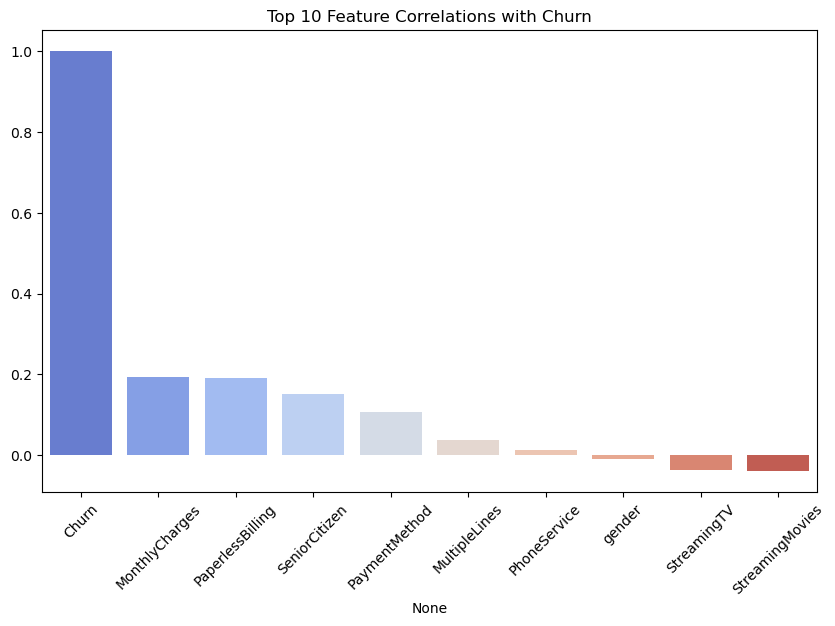

In [36]:
# Heatmap alternative: Barplot of correlations with Churn

# Drop non-numeric columns like customerID
numeric_df = df.drop(columns=['customerID'])

# Compute correlations with target variable 'Churn'
churn_corr = numeric_df.corr()['Churn'].sort_values(ascending=False)

# Plot top 10 strongest correlations for clarity
plt.figure(figsize=(10,6))
sns.barplot(
    x=churn_corr.index[:10],   # top 10 features
    y=churn_corr.values[:10],
    hue=churn_corr.index[:10], # assign hue to avoid warning
    palette="coolwarm",
    legend=False
)
plt.xticks(rotation=45)
plt.title("Top 10 Feature Correlations with Churn")
plt.show()


In [37]:

# Evaluate models with detailed metrics
models = {
    "Logistic Regression": log_reg,
    "Decision Tree": dtree,
    "Random Forest": rf
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append([name, acc, prec, rec, f1])

# Convert results to DataFrame for easy comparison
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"])
print("\nModel Comparison:\n", results_df)

# Highlight best model
best_model = results_df.loc[results_df['Accuracy'].idxmax()]
print(f"\n✅ Final Selected Model: {best_model['Model']} (Accuracy: {best_model['Accuracy']:.2f})")



Model Comparison:
                  Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.815472   0.677116  0.579088  0.624277
1        Decision Tree  0.731015   0.492188  0.506702  0.499339
2        Random Forest  0.789212   0.638686  0.469169  0.540958

✅ Final Selected Model: Logistic Regression (Accuracy: 0.82)


In [42]:
# Predict churn on the test set using Logistic Regression
y_pred = log_reg.predict(X_test)
y_pred_prob = log_reg.predict_proba(X_test)[:,1] * 100  # churn probability %

# Get the corresponding test customers from the original DataFrame
test_customers = df.iloc[y_test.index].copy()   # safe copy

# Add predictions and probabilities
test_customers.loc[:, 'PredictedChurn'] = y_pred
test_customers.loc[:, 'ChurnProbability'] = y_pred_prob

# Show only customers predicted to churn
churned_customers = test_customers[test_customers['PredictedChurn'] == 1]

print("\nCustomers predicted to churn (Logistic Regression):")
print(churned_customers[['customerID', 'ChurnProbability']].head(10))  # show first 10 for clarity

# Calculate overall churn percentage in the test set
churn_rate = (churned_customers.shape[0] / test_customers.shape[0]) * 100
print(f"\n📊 Overall predicted churn rate (Logistic Regression): {churn_rate:.2f}% of customers in the test set")

# Optional: Save full list to CSV
churned_customers[['customerID', 'ChurnProbability']].to_csv("log_reg_churn_predictions.csv", index=False)
print("\n✅ Churn predictions with probabilities saved to log_reg_churn_predictions.csv")



Customers predicted to churn (Logistic Regression):
      customerID  ChurnProbability
185   1024-GUALD         65.151400
1807  6910-HADCM         57.969433
3801  5914-DVBWJ         50.284523
6179  6328-ZPBGN         77.144767
4640  1853-UDXBW         63.014483
3328  1640-PLFMP         66.942526
3469  9402-ORRAH         73.172912
4645  5219-YIPTK         60.079951
1662  2058-DCJBE         62.130025
4343  7130-VTEWQ         71.420463

📊 Overall predicted churn rate (Logistic Regression): 22.64% of customers in the test set

✅ Churn predictions with probabilities saved to log_reg_churn_predictions.csv
